In [2]:
def bloch_ode(tau, y, delta, gamma, omega=1.0):
    u, v, w =y # has to be this way because its u=y[0] etc

    # can have time dep delta:
    delta = delta(tau) if callable(delta) else delta # evaluates delta(tau) at current time if it is a function, otherwise its just the constant delta

    u_dot = delta*v - 0.5*gamma 
    v_dot = - delta*u + omega*w - 0.5*gamma*v
    w_dot = -omega*v - gamma*(w-1) # convention w=rho_11-rho22

    return [u_dot, v_dot, w_dot]

In [3]:
from scipy.integrate import solve_ivp
import numpy as np

y0=[0,0,1] # boundary condition
tau_length = (0.0, 20*np.pi) # length of one Rabi-oscillation is 2pi because of scaling (tau=t*omega)
tau_points = np.linspace(tau_length[0], tau_length[1], 1000)


In [14]:
import matplotlib.pyplot as plt

phi, theta = np.mgrid[0.0:np.pi:30j, 0.0:2.0*np.pi:30j]
xs = np.sin(phi) * np.cos(theta)
ys = np.sin(phi) * np.sin(theta)
zs = np.cos(phi)

def plotter(sol, title=""):
    u, v, w = sol.y
    t_periods = sol.t / (2 * np.pi)

    fig = plt.figure(figsize=(10, 4.5))

    # 3D path
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    ax1.plot_wireframe(xs, ys, zs, color="gray", alpha=0.15)
    ax1.plot(u, v, w, color="mediumorchid", lw=1.5) # plots path of bloch vector
    ax1.set_xlim([-1, 1]); ax1.set_ylim([-1, 1]); ax1.set_zlim([-1, 1])
    ax1.set_xlabel("u"); ax1.set_ylabel("v"); ax1.set_zlabel("w")
    ax1.set_title(title)

    # time dynamics
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.plot(t_periods, u, label="u", color="darkcyan")
    ax2.plot(t_periods, v, label="v", color="firebrick")
    ax2.plot(t_periods, w, label="w", color="yellowgreen")
    ax2.set_xlabel(r"$\tau / 2\pi$ (Number of Rabi periods)")
    ax2.set_ylabel("u, v, w values")
    ax2.set_ylim([-1.05, 1.05])
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

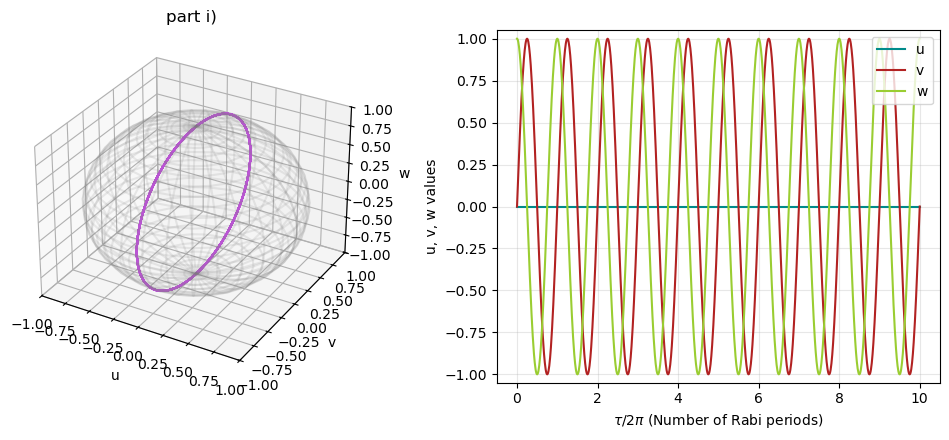

In [15]:
# part i)

gamma_i = 0
delta_i = 0

# for solver, need function of tau,y

def converter_i(tau,y):
    return bloch_ode(tau, y, delta_i, gamma_i, omega=1.0) 

sol_i = solve_ivp(
    fun=converter_i, # fun is a function
    t_span=tau_length,
    y0=y0,
    t_eval=tau_points,
    method='RK45',   # Runge-Kutta
    rtol=1e-8,
    atol=1e-10
)

#u_i, v_i, w_i = sol_i.y_i

plotter(sol_i, "part i)")

Bloch vector rotates around y (v) axis.

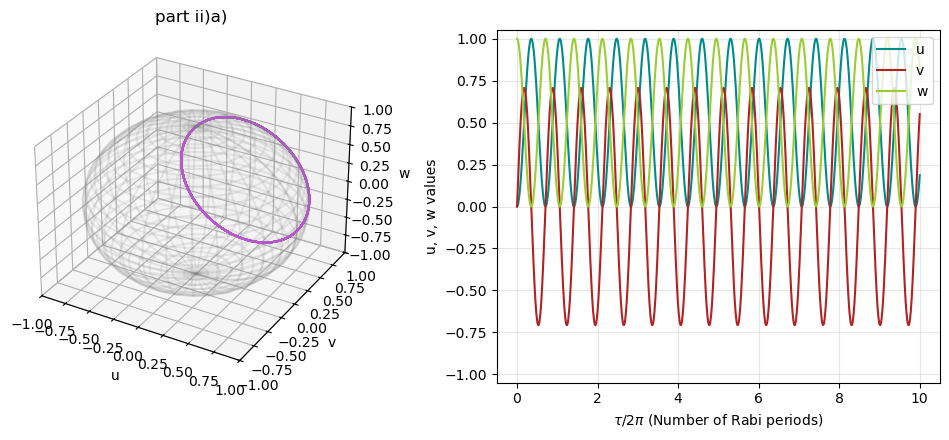

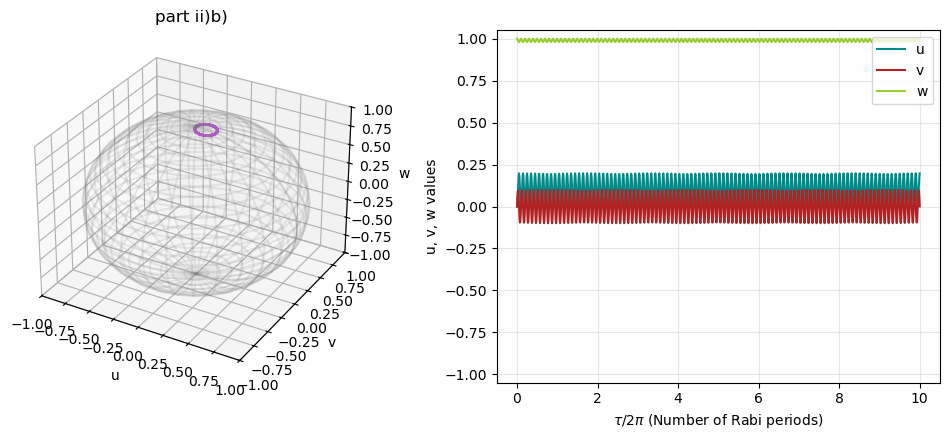

In [16]:
# part ii) 

# case a) delta = omega, case b) delta = 10*omega

omega=1.0 # think this is arbitrary

delta_a = omega
delta_b = 10*omega
gamma_ii=0

#case a:

def converter_ii_a(tau,y):
    return bloch_ode(tau, y, delta_a, gamma_ii, omega=1.0) 

sol_ii_a = solve_ivp(
    fun=converter_ii_a, # fun is a function
    t_span=tau_length,
    y0=y0,
    t_eval=tau_points,
    method='RK45',   # Runge-Kutta
    rtol=1e-8,
    atol=1e-10
)

plotter(sol_ii_a, "part ii)a)")

# case b:

def converter_ii_b(tau,y):
    return bloch_ode(tau, y, delta_b, gamma_ii, omega=1.0) 

sol_ii_a = solve_ivp(
    fun=converter_ii_b, # fun is a function
    t_span=tau_length,
    y0=y0,
    t_eval=tau_points,
    method='RK45',   # Runge-Kutta
    rtol=1e-8,
    atol=1e-10
)

plotter(sol_ii_a, "part ii)b)")

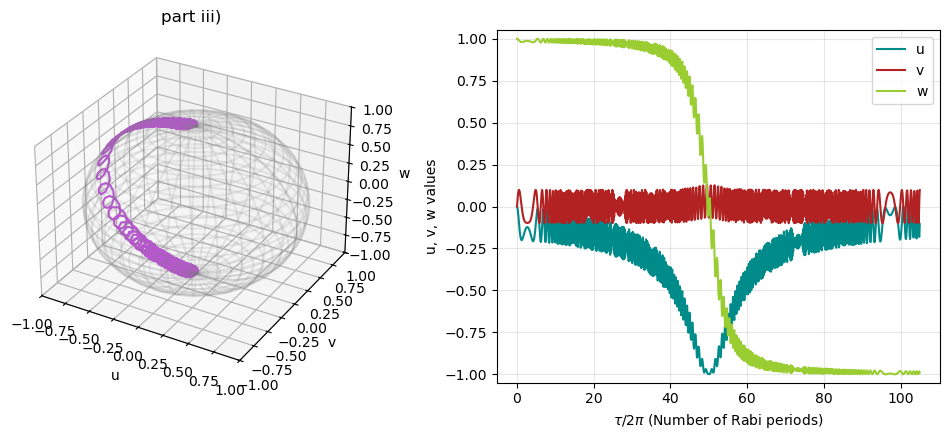

In [17]:
# part iii)
# Detuning delta is changed linearly from -10*omega to 10*omega in the time interval delta_tau = 200pi

tau_points_iii = np.linspace(0, 210*np.pi, 1000)
tau_length_iii = (0, 210*np.pi)
gamma_iii =0

def delta(tau):
    return tau*20*omega/(200*np.pi) - 10*omega

def converter_iii(tau,y):
    return bloch_ode(tau, y, delta, gamma_iii, omega=1.0) 

sol_iii = solve_ivp(
    fun=converter_iii, # fun is a function
    t_span=tau_length_iii,
    y0=y0,
    t_eval=tau_points_iii,
    method='RK45',   # Runge-Kutta
    rtol=1e-8,
    atol=1e-10
)

plotter(sol_iii, "part iii)")
    



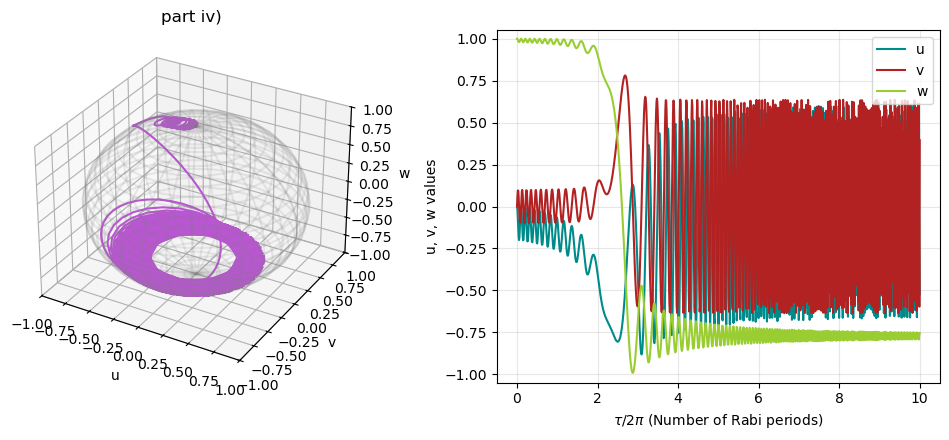

In [18]:
# part iv) 
# delta changed from same amount in time interval 2*pi*5

tau_points_iv = np.linspace(0, 20*np.pi, 1000)
tau_length_iv = (0, 20*np.pi)
gamma_iv =0

def delta(tau):
    return tau*20*omega/(2*np.pi*5) - 10*omega

def converter_iv(tau,y):
    return bloch_ode(tau, y, delta, gamma_iv, omega=1.0) 

sol_iv = solve_ivp(
    fun=converter_iv, # fun is a function
    t_span=tau_length_iv,
    y0=y0,
    t_eval=tau_points_iv,
    method='RK45',   # Runge-Kutta
    rtol=1e-8,
    atol=1e-10
)

plotter(sol_iv, "part iv)")

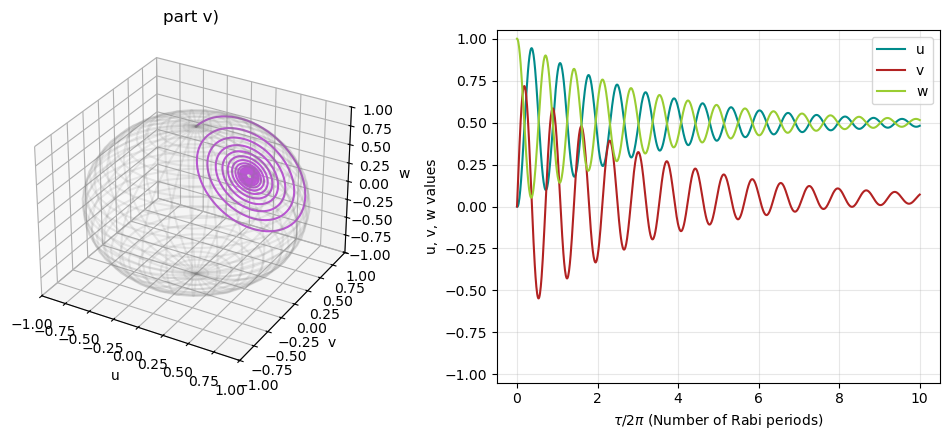

Final Bloch vector length: 0.708578


In [19]:
# part v) 
# delta = omega and gamma = 0.1*omega

delta_v = omega
gamma_v = 0.1*omega

def converter_v(tau,y):
    return bloch_ode(tau, y, delta_v, gamma_v, omega=1.0) 

sol_v = solve_ivp(
    fun=converter_v, # fun is a function
    t_span=tau_length,
    y0=y0,
    t_eval=tau_points,
    method='RK45',   # Runge-Kutta
    rtol=1e-8,
    atol=1e-10
)

plotter(sol_v, "part v)")

u_final, v_final, w_final = sol_v.y[:, -1]

R_final = np.sqrt(u_final**2 + v_final**2 + w_final**2)

print(f"Final Bloch vector length: {R_final:.6f}")